In [17]:
import torch

from torch import nn
from torch.utils.data import DataLoader,random_split
from torchvision import datasets,transforms

import matplotlib.pyplot as plt

In [18]:
transform=transforms.ToTensor()
full_train_dataset=datasets.MNIST(root="./data",train=True,download=True,transform=transform)
test_dataset=datasets.MNIST(root="./data",train=False,download=True,transform=transform)

print("Train samples:",len(full_train_dataset))
print("Test samples:",len(test_dataset))

Train samples: 60000
Test samples: 10000


In [19]:
image,label=full_train_dataset[0]
print("Image shape:",image.shape)
print("Label:",label)
print("Pixel min:",image.min().item())
print("Pixel max:",image.max().item())

Image shape: torch.Size([1, 28, 28])
Label: 5
Pixel min: 0.0
Pixel max: 1.0


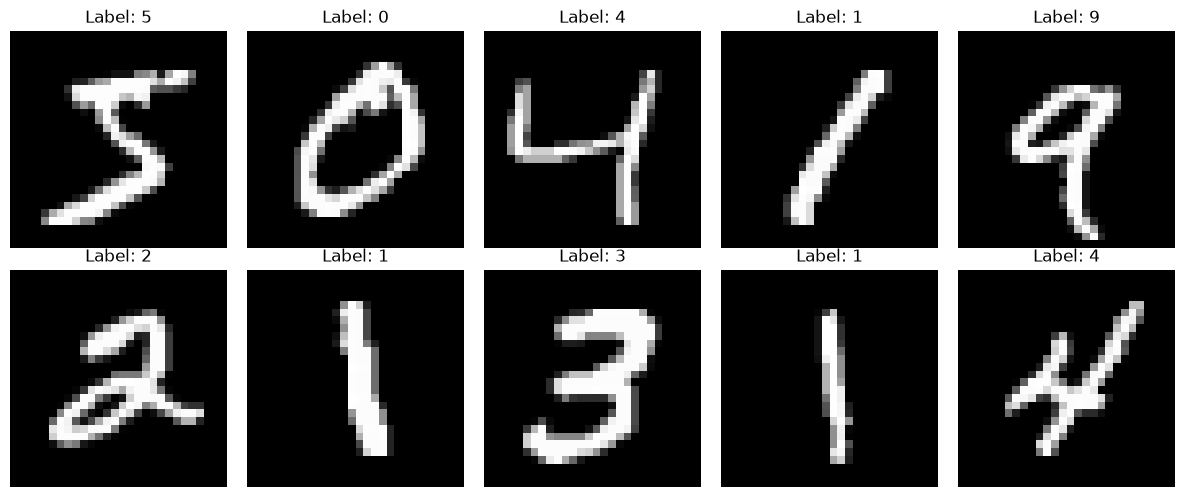

In [20]:
fig,axes=plt.subplots(2,5,figsize=(12,5))

for i,ax in enumerate(axes.flat):
    image,label=full_train_dataset[i]

    ax.imshow(image.squeeze(0),cmap="gray")

    ax.set_title(f"Label: {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [21]:
torch.manual_seed(42)

train_dataset,val_dataset=random_split(
    full_train_dataset,
    [50000,10000],
    generator=torch.Generator().manual_seed(42)
)

train_loader=DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

val_loader=DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False
)

test_loader=DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 782
Validation batches: 157
Test batches: 157


In [22]:
class MNISTClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.layers=nn.Sequential(
            nn.Flatten(),
            nn.Linear(784,256),
            nn.Linear(256,128),
            nn.Linear(128,10),
            nn.ReLU()
        )

    def forward(self,x):
        return self.layers

device=torch.device("cuda" if torch.cuda.is_available() else "cpu")

model=MNISTClassifier().to(device)
print(model)


MNISTClassifier(
  (layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): Linear(in_features=128, out_features=10, bias=True)
    (4): ReLU()
  )
)


In [23]:
device

device(type='cuda')

In [25]:
total__params=sum(p.numel() for p in model.parameters())
print(total__params)

235146


In [27]:
criterion=nn.CrossEntropyLoss()
optimier=torch.optim.Adam(model.parameters(),lr=0.001)